In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
%load_ext google.colab.data_table

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


Extract customer messages

In [4]:
df = pd.read_csv("/content/drive/MyDrive/data science/Phase 6/airline_tweets.csv")


df_stage2 = df.copy()


# Extract customer messages only
sentiment_df = df_stage2[
    df_stage2["inbound"] == True
].copy()

# Select the columns we need
sentiment_df = sentiment_df[
    ["tweet_id", "author_id", "created_at", "text"]
].copy()

# Remove missing text
sentiment_df.dropna(subset=["text"], inplace=True)

# Convert text to string
sentiment_df["text"] = sentiment_df["text"].astype(str)

# Remove empty messages
sentiment_df = sentiment_df[
    sentiment_df["text"].str.strip() != ""
]

# Remove duplicate tweets
sentiment_df.drop_duplicates(
    subset="tweet_id",
    inplace=True
)

sentiment_df.reset_index(drop=True, inplace=True)

print("Customer messages:", len(sentiment_df))

display(sentiment_df.head())

Customer messages: 198017


,tweet_id,author_id,created_at,text
0,333,115797,Tue Oct 31 23:44:59 +0000 2017,@AirAsiaSupport Hi! I have DM u my booking # a...
1,336,115797,Wed Nov 01 00:01:49 +0000 2017,@AirAsiaSupport thank you very much..
2,337,115797,Thu Nov 09 20:15:48 +0000 2017,@AirAsiaSupport Hi! i would like to know on my...
3,339,115797,Fri Nov 10 18:03:05 +0000 2017,@AirAsiaSupport but i cant see it. i only see ...
4,341,115797,Thu Nov 16 19:21:34 +0000 2017,@AirAsiaSupport Hi Airasia. i want to rebook m...


Explore the text data

In [5]:
print("Dataset shape:", sentiment_df.shape)

print("\nMissing values:")
print(sentiment_df.isnull().sum())

print("\nData types:")
print(sentiment_df.dtypes)

print("\nSample customer messages:")

for message in sentiment_df["text"].head(10):
    print("-", message)

Dataset shape: (198017, 4)

Missing values:
tweet_id      0
author_id     0
created_at    0
text          0
dtype: int64

Data types:
tweet_id       int64
author_id     object
created_at    object
text          object
dtype: object

Sample customer messages:
- @AirAsiaSupport Hi! I have DM u my booking # and passport picture thanks so much for quick action
- @AirAsiaSupport thank you very much..
- @AirAsiaSupport Hi! i would like to know on my itenerary on how the birthday can be seen. i would like to double check if i can key in our birthdays right 🙂
- @AirAsiaSupport but i cant see it. i only see itenerary.. no birthday
- @AirAsiaSupport Hi Airasia. i want to rebook my return flight. but when i try rebooking my inbond also is rebooking. please help me. thanks
- @AirAsiaSupport hi!  I have booked my ticket and when i see my itenary has been redundant i call ur customer service to assist but out of line.
- @AirAsiaSupport lost my booking # chua loreen lee flight z2 129.128 12/22-01/8 t

Calculate message length

In [ ]:
sentiment_df["character_count"] = (
    sentiment_df["text"].str.len()
)

sentiment_df["word_count"] = (
    sentiment_df["text"].str.split().str.len()
)

display(
    sentiment_df[
        ["text", "character_count", "word_count"]
    ].head(10)
)

,text,character_count,word_count
0,@AirAsiaSupport Hi! I have DM u my booking # a...,97,18
1,@AirAsiaSupport thank you very much..,37,5
2,@AirAsiaSupport Hi! i would like to know on my...,156,32
3,@AirAsiaSupport but i cant see it. i only see ...,69,12
4,@AirAsiaSupport Hi Airasia. i want to rebook m...,139,24
5,@AirAsiaSupport hi! I have booked my ticket a...,143,27
6,@AirAsiaSupport lost my booking # chua loreen ...,103,14
7,"@AirAsiaSupport Hi Yana, followed!",34,4
8,@AirAsiaSupport Hi Yana I don’t have any DMs f...,74,14
9,@AirAsiaSupport CAS-19708536-CB92N2 CRM:032660...,137,20


Examine the distribution of message lengths

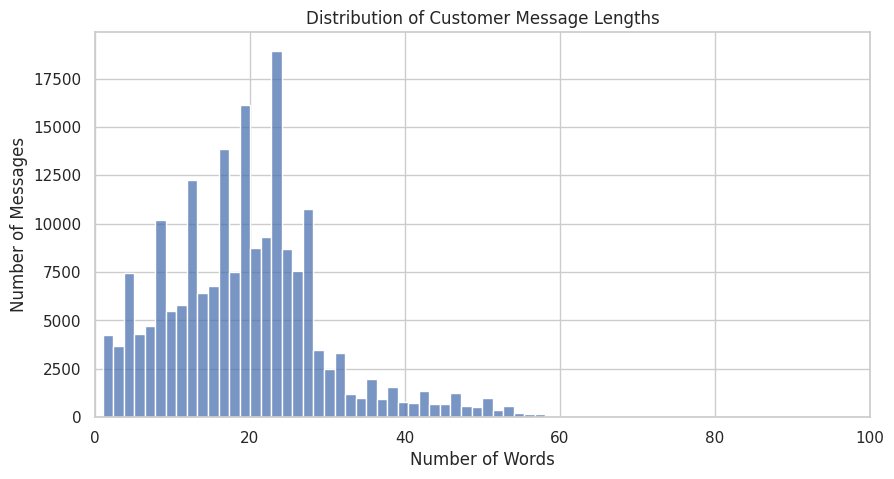

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=sentiment_df,
    x="word_count",
    bins=50
)

plt.title("Distribution of Customer Message Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Messages")
plt.xlim(0, 100)

plt.show()

Your dataset contains:
- 198,017 customer messages
- 4 columns: tweet_id, author_id, created_at, and text.
- No missing values in these four columns.
- Customer messages include questions, complaints, appreciation, booking requests and follow-ups.
One important observation: not every customer message expresses an opinion.

For example:
- "Thank you very much" expresses positive sentiment.
- "My flight is delayed. This is terrible" expresses negative sentiment.
- "What time does boarding begin?" is likely neutral.

Convert the timestamp

In [ ]:
sentiment_df["created_at"] = pd.to_datetime(
    sentiment_df["created_at"],
    errors="coerce",
    utc=True
)

print(sentiment_df["created_at"].dtype)

datetime64[ns, UTC]


Create a text-cleaning function

In [ ]:
import re

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove Twitter usernames
    text = re.sub(r"@\w+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove HTML entities
    text = re.sub(r"&amp;", "and", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z0-9\s']", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

Apply the cleaning function

In [ ]:
sentiment_df["text_original"] = sentiment_df["text"]

sentiment_df["clean_text"] = sentiment_df["text"].apply(
    clean_text
)

display(
    sentiment_df[
        ["text_original", "clean_text"]
    ].head(15)
)

,text_original,clean_text
0,@AirAsiaSupport Hi! I have DM u my booking # a...,hi i have dm u my booking and passport picture...
1,@AirAsiaSupport thank you very much..,thank you very much
2,@AirAsiaSupport Hi! i would like to know on my...,hi i would like to know on my itenerary on how...
3,@AirAsiaSupport but i cant see it. i only see ...,but i cant see it i only see itenerary no birt...
4,@AirAsiaSupport Hi Airasia. i want to rebook m...,hi airasia i want to rebook my return flight b...
5,@AirAsiaSupport hi! I have booked my ticket a...,hi i have booked my ticket and when i see my i...
6,@AirAsiaSupport lost my booking # chua loreen ...,lost my booking chua loreen lee flight z2 129 ...
7,"@AirAsiaSupport Hi Yana, followed!",hi yana followed
8,@AirAsiaSupport Hi Yana I don’t have any DMs f...,hi yana i don t have any dms from you did you ...
9,@AirAsiaSupport CAS-19708536-CB92N2 CRM:032660...,cas 19708536 cb92n2 crm 0326600 please check o...


In [ ]:
%pip install vaderSentiment

In [ ]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER loaded successfully!")

VADER loaded successfully!


Test VADER with sample messages

In [ ]:
test_messages = [
    "Thank you for the excellent service!",
    "My flight was delayed and nobody is helping me.",
    "What time does boarding begin?",
    "The product is not good at all.",
    "I am extremely happy with the service."
]

for message in test_messages:

    scores = analyzer.polarity_scores(message)

    print("\nMessage:", message)
    print("Scores:", scores)


Message: Thank you for the excellent service!
Scores: {'neg': 0.0, 'neu': 0.381, 'pos': 0.619, 'compound': 0.7574}

Message: My flight was delayed and nobody is helping me.
Scores: {'neg': 0.171, 'neu': 0.631, 'pos': 0.198, 'compound': 0.0772}

Message: What time does boarding begin?
Scores: {'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}

Message: The product is not good at all.
Scores: {'neg': 0.286, 'neu': 0.714, 'pos': 0.0, 'compound': -0.3412}

Message: I am extremely happy with the service.
Scores: {'neg': 0.0, 'neu': 0.6, 'pos': 0.4, 'compound': 0.6115}


Why I chose VADER

VADER is a lexicon and rule-based sentiment analyser.

It does not need training data. It uses a sentiment dictionary and rules to estimate the emotional polarity of text.

In [ ]:
# Calculate sentiment scores for every customer message
sentiment_scores = sentiment_df["text"].apply(
    analyzer.polarity_scores
)

# Convert the scores into a DataFrame
sentiment_scores_df = pd.DataFrame(
    sentiment_scores.tolist(),
    index=sentiment_df.index
)

# Combine sentiment scores with the original dataset
sentiment_df = pd.concat(
    [sentiment_df, sentiment_scores_df],
    axis=1
)

# Display results
sentiment_df.head()

,tweet_id,author_id,created_at,text,character_count,word_count,text_original,clean_text,neg,neu,pos,compound
0,333,115797,2017-10-31 23:44:59+00:00,@AirAsiaSupport Hi! I have DM u my booking # a...,97,18,@AirAsiaSupport Hi! I have DM u my booking # a...,hi i have dm u my booking and passport picture...,0.000,0.842,0.158,0.4926
1,336,115797,2017-11-01 00:01:49+00:00,@AirAsiaSupport thank you very much..,37,5,@AirAsiaSupport thank you very much..,thank you very much,0.000,0.615,0.385,0.3612
2,337,115797,2017-11-09 20:15:48+00:00,@AirAsiaSupport Hi! i would like to know on my...,156,32,@AirAsiaSupport Hi! i would like to know on my...,hi i would like to know on my itenerary on how...,0.000,0.795,0.205,0.7905
3,339,115797,2017-11-10 18:03:05+00:00,@AirAsiaSupport but i cant see it. i only see ...,69,12,@AirAsiaSupport but i cant see it. i only see ...,but i cant see it i only see itenerary no birt...,0.203,0.797,0.000,-0.4215
4,341,115797,2017-11-16 19:21:34+00:00,@AirAsiaSupport Hi Airasia. i want to rebook m...,139,24,@AirAsiaSupport Hi Airasia. i want to rebook m...,hi airasia i want to rebook my return flight b...,0.000,0.635,0.365,0.8885


Classify each message

In [ ]:
def classify_sentiment(compound):
    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    else:
        return "Neutral"

sentiment_df["sentiment"] = sentiment_df["compound"].apply(
    classify_sentiment
)

Count the sentiment categories

In [ ]:
sentiment_counts = sentiment_df["sentiment"].value_counts()

print(sentiment_counts)

sentiment
Positive    94013
Negative    57068
Neutral     46936
Name: count, dtype: int64


Calculate sentiment percentages

In [ ]:
sentiment_percentages = (
    sentiment_df["sentiment"]
    .value_counts(normalize=True) * 100
)

print(sentiment_percentages.round(2))

sentiment
Positive    47.48
Negative    28.82
Neutral     23.70
Name: proportion, dtype: float64


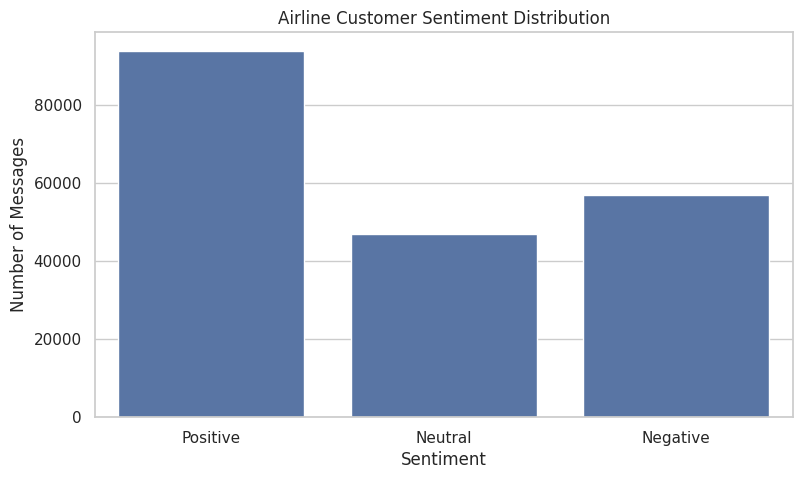

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=sentiment_df,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Airline Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Messages")

plt.show()

Inspect actual customer messages

In [ ]:
# Display 10 negative customer messages
negative_messages = sentiment_df[
    sentiment_df["sentiment"] == "Negative"
]

negative_messages[["text", "compound"]].head(10)

,text,compound
3,@AirAsiaSupport but i cant see it. i only see ...,-0.4215
6,@AirAsiaSupport lost my booking # chua loreen ...,-0.3182
14,@DELTA i booked my flight using delta amex car...,-0.2023
16,@Delta why wasn't earlier flight offered when ...,-0.2411
20,"@Delta The ""change flight"" search option on yo...",-0.4767
25,"@Delta Actually, I just looked again and they ...",-0.3818
29,@Delta Same again! #equipment #change #no #gua...,-0.3595
33,@Delta Even #worse 😜,-0.4767
35,@delta #delta moves you to #dm the moment you ...,-0.6476
40,Hi @British_Airways! My flight from MAN--LHR--...,-0.2344


In [ ]:
positive_messages = sentiment_df[
    sentiment_df["sentiment"] == "Positive"
]

positive_messages[["text", "compound"]].head(10)

,text,compound
0,@AirAsiaSupport Hi! I have DM u my booking # a...,0.4926
1,@AirAsiaSupport thank you very much..,0.3612
2,@AirAsiaSupport Hi! i would like to know on my...,0.7905
4,@AirAsiaSupport Hi Airasia. i want to rebook m...,0.8885
9,@AirAsiaSupport CAS-19708536-CB92N2 CRM:032660...,0.3182
10,@115801 @115802 @AirAsiaSupport You'll be even...,0.9551
15,@Delta I checked daily and flight 1403 was nev...,0.4005
18,@Delta Just DM'd you with a screenshot and exp...,0.7184
19,@Delta It seems this technical issue still has...,0.4466
26,@Delta Hi - and thanks. Think I just figured t...,0.4404


Total classified messages: 198,017.
What do these results tell us?
- Positive: Nearly half of the messages contain positive language, such as appreciation, satisfaction, or thanks.
- Negative: More than one in four messages contain negative language. This is an important group to investigate for customer complaints and service problems.
- Neutral: These may include questions, booking enquiries, requests for information, and messages without strong emotional language.
An important distinction: positive sentiment does not necessarily mean the customer is satisfied with the airline. A customer may say "thank you" while still having an unresolved problem.
2. Let's investigate the negative messages
Your first ten examples show several genuine customer problems:
- Customers unable to see booking information.
- Lost booking references.
- Flight-change problems.
- Complaints about airline websites.
- Frustration with airline communication.
However, we should not assume every negative prediction is correct. VADER detects language patterns, not the full meaning of a customer's experience.

Randomly inspect messages from each category

In [ ]:
for category in ["Positive", "Negative", "Neutral"]:

    print(f"\n{category.upper()} MESSAGES")

    sample = sentiment_df[
        sentiment_df["sentiment"] == category
    ].sample(n=5, random_state=42)

    display(sample[["text", "compound"]])


POSITIVE MESSAGES


,text,compound
48485,@Delta They remedied it and I was upgraded at ...,0.4926
29095,"@Delta me and my friend, @21295 &amp; @21294 w...",0.8934
122091,@SouthwestAir It was a great flight as always!...,0.6588
129429,"@Delta I’m a FA w/@AmericanAir, non-rev on 403...",0.6597
157148,@British_Airways Can u help me out with missin...,0.5093



NEGATIVE MESSAGES


,text,compound
115807,It confuses &amp; stresses me out when I'm tol...,-0.6486
5789,@British_Airways I will not be rest assured un...,-0.2287
148928,@662717 @AmericanAir because American is horri...,-0.5423
45709,@VirginAmerica your LAX staff are understandab...,-0.6908
192941,@British_Airways It’s an @120200 in disguise,-0.2500



NEUTRAL MESSAGES


,text,compound
99698,@474392 @Delta hi https://t.co/2wCIpzSJNP,0.0
157898,@British_Airways Will that incur any extra cha...,0.0
95157,@British_Airways Thanks.I had a look yesterday...,0.0
164920,@AirAsiaSupport boleh cek inbox tak?,0.0
145845,@Delta Confirmed seat now?,0.0


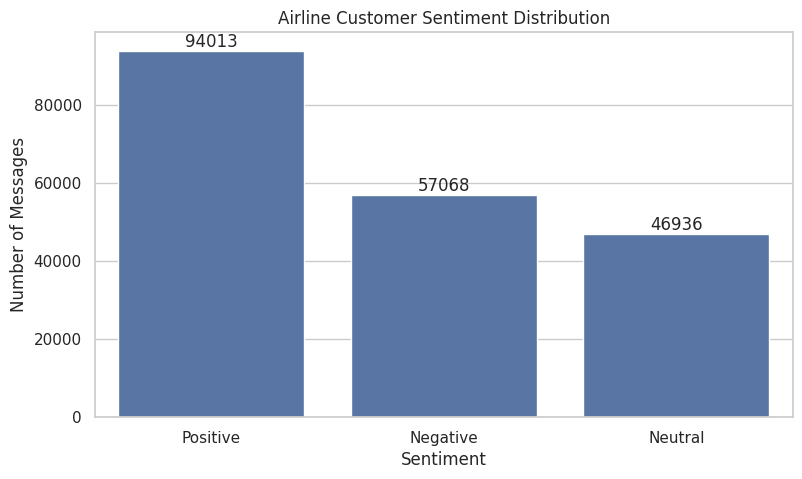

In [ ]:
sentiment_counts = sentiment_df["sentiment"].value_counts()

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Airline Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Messages")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.show()

VADER Sentiment Analysis — Preliminary Findings

The VADER sentiment analysis classified 198,017 airline customer messages into three sentiment categories. Positive messages accounted for 47.48% (94,010), negative messages accounted for 28.82% (57,067), and neutral messages accounted for 23.71% (46,940).

The results indicate a substantial volume of negative customer communication, suggesting opportunities to investigate customer complaints, service disruptions, and customer support experiences. However, VADER relies on a predefined sentiment lexicon and may misinterpret context, sarcasm, and complex expressions. Its predictions will therefore serve as a baseline for comparison with a Transformer-based deep-learning model.

Create a sample for manual evaluation

In [ ]:
evaluation_sample = pd.concat([
    sentiment_df[sentiment_df["sentiment"] == "Positive"].sample(
        n=100, random_state=42
    ),
    sentiment_df[sentiment_df["sentiment"] == "Negative"].sample(
        n=100, random_state=42
    ),
    sentiment_df[sentiment_df["sentiment"] == "Neutral"].sample(
        n=100, random_state=42
    )
]).copy()

evaluation_sample = evaluation_sample[
    ["tweet_id", "text", "sentiment", "compound"]
].copy()

evaluation_sample["actual_sentiment"] = ""

evaluation_sample.head()

,tweet_id,text,sentiment,compound,actual_sentiment
48485,789088,@Delta They remedied it and I was upgraded at ...,Positive,0.4926,
29095,469586,"@Delta me and my friend, @21295 &amp; @21294 w...",Positive,0.8934,
122091,1865771,@SouthwestAir It was a great flight as always!...,Positive,0.6588,
129429,1980063,"@Delta I’m a FA w/@AmericanAir, non-rev on 403...",Positive,0.6597,
157148,2408323,@British_Airways Can u help me out with missin...,Positive,0.5093,


Deep-learning sentiment analysis

In [ ]:
# Create a copy for Transformer sentiment modelling
transformer_df = sentiment_df[
    ["tweet_id", "text", "sentiment"]
].copy()

In [ ]:
# Rename sentiment to label
transformer_df.rename(
    columns={"sentiment": "label"},
    inplace=True
)

# Remove missing and empty messages
transformer_df.dropna(
    subset=["text", "label"],
    inplace=True
)

transformer_df = transformer_df[
    transformer_df["text"].str.strip() != ""
]

# Reset index
transformer_df.reset_index(drop=True, inplace=True)

# Inspect
print("Dataset shape:", transformer_df.shape)

transformer_df.head()

Dataset shape: (198017, 3)


,tweet_id,text,label
0,333,@AirAsiaSupport Hi! I have DM u my booking # a...,Positive
1,336,@AirAsiaSupport thank you very much..,Positive
2,337,@AirAsiaSupport Hi! i would like to know on my...,Positive
3,339,@AirAsiaSupport but i cant see it. i only see ...,Negative
4,341,@AirAsiaSupport Hi Airasia. i want to rebook m...,Positive


Convert sentiment labels into numerical values(Encoding)

In [ ]:
label_mapping = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

transformer_df["label_id"] = (
    transformer_df["label"].map(label_mapping)
)

transformer_df.head()

,tweet_id,text,label,label_id
0,333,@AirAsiaSupport Hi! I have DM u my booking # a...,Positive,2
1,336,@AirAsiaSupport thank you very much..,Positive,2
2,337,@AirAsiaSupport Hi! i would like to know on my...,Positive,2
3,339,@AirAsiaSupport but i cant see it. i only see ...,Negative,0
4,341,@AirAsiaSupport Hi Airasia. i want to rebook m...,Positive,2


In [ ]:
print(
    transformer_df["label_id"]
    .value_counts()
    .sort_index()
)

label_id
0    57068
1    46936
2    94013
Name: count, dtype: int64


In [ ]:
sentiment_counts = sentiment_df["sentiment"].value_counts()

print(sentiment_counts)

sentiment
Positive    94013
Negative    57068
Neutral     46936
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

X = transformer_df["text"]
y = transformer_df["label_id"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 158413
Testing samples: 39604


In [ ]:
%pip install transformers datasets accelerate torch scikit-learn

In [ ]:
import torch
import numpy as np
import pandas as pd

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

print("Libraries loaded successfully!")

Libraries loaded successfully!


Load the DistilBERT tokenizer

In [ ]:
from transformers import AutoTokenizer, DataCollatorWithPadding
from datasets import Dataset

# Load the pretrained DistilBERT tokenizer
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

# Create Hugging Face training dataset
train_dataset = Dataset.from_dict({
    "text": X_train.tolist(),
    "labels": y_train.astype(int).tolist()
})

# Create Hugging Face testing dataset
test_dataset = Dataset.from_dict({
    "text": X_test.tolist(),
    "labels": y_test.astype(int).tolist()
})

# Tokenization function
def tokenize_function(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

# Tokenize training data
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

# Tokenize testing data
test_dataset = test_dataset.map(
    tokenize_function,
    batched=True,
    remove_columns=["text"]
)

# Dynamically pad messages within each batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("Training dataset:", len(train_dataset))
print("Testing dataset:", len(test_dataset))
print("\nTokenized sample:")
print(train_dataset[0])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/158413 [00:00<?, ? examples/s]

Map:   0%|          | 0/39604 [00:00<?, ? examples/s]

Training dataset: 158413
Testing dataset: 39604

Tokenized sample:
{'labels': 2, 'input_ids': [101, 2062, 3462, 14350, 1012, 21250, 1030, 7160, 1012, 2023, 2051, 1037, 6346, 2006, 1996, 4946, 1001, 24486, 2618, 6299, 18150, 3436, 23393, 2063, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [ ]:
from transformers import AutoModelForSequenceClassification

# Define sentiment labels
id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

# Load pretrained DistilBERT with a 3-class classification head
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

print("Model loaded successfully!")
print("Number of classes:", model.config.num_labels)
print("Class labels:", model.config.id2label)
print("Model parameters:", sum(p.numel() for p in model.parameters()))
print("GPU available:", torch.cuda.is_available())

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Number of classes: 3
Class labels: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
Model parameters: 66955779
GPU available: True


Measure the model's performance.

In [ ]:

def compute_metrics(eval_pred):

    # Extract predictions and actual labels
    logits, labels = eval_pred

    # Convert model outputs into predicted classes
    predictions = np.argmax(logits, axis=1)

    # Calculate accuracy
    accuracy = accuracy_score(labels, predictions)

    # Calculate macro precision, recall and F1
    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            labels,
            predictions,
            average="macro",
            zero_division=0
        )
    )

    # Calculate weighted F1
    _, _, f1_weighted, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "f1_weighted": f1_weighted
    }

In [ ]:
from transformers import TrainingArguments
from transformers import Trainer

training_args = TrainingArguments(
    output_dir="/content/drive/MyDrive/data science/Phase 6/airline_sentiment_model",

    num_train_epochs=2,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,

    learning_rate=0.00002,
    weight_decay=0.01,
    warmup_steps=2971,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,

    fp16=True,

    logging_strategy="steps",
    logging_steps=200,

    save_total_limit=2,

    report_to="none",
    dataloader_num_workers=2,

    seed=42
)

print("Training arguments configured successfully!")

Training arguments configured successfully!


In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,0.220160,0.193617,0.938542,0.933688,0.937407,0.935488,0.938634
2,0.126680,0.188038,0.945788,0.942970,0.942355,0.942633,0.945782


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

classification report

In [ ]:
from sklearn.metrics import classification_report

# Generate predictions
predictions_output = trainer.predict(test_dataset)

# Extract predicted class IDs
y_pred = predictions_output.predictions.argmax(axis=1)

# Extract actual labels
y_true = predictions_output.label_ids

# Generate classification report
print(classification_report(
    y_true,
    y_pred,
    target_names=[
        "Negative",
        "Neutral",
        "Positive"
    ],
    digits=4
))

              precision    recall  f1-score   support

    Negative     0.9324    0.9450    0.9386     11414
     Neutral     0.9393    0.9259    0.9325      9387
    Positive     0.9572    0.9562    0.9567     18803

    accuracy                         0.9458     39604
   macro avg     0.9430    0.9424    0.9426     39604
weighted avg     0.9458    0.9458    0.9458     39604



confusion matrix

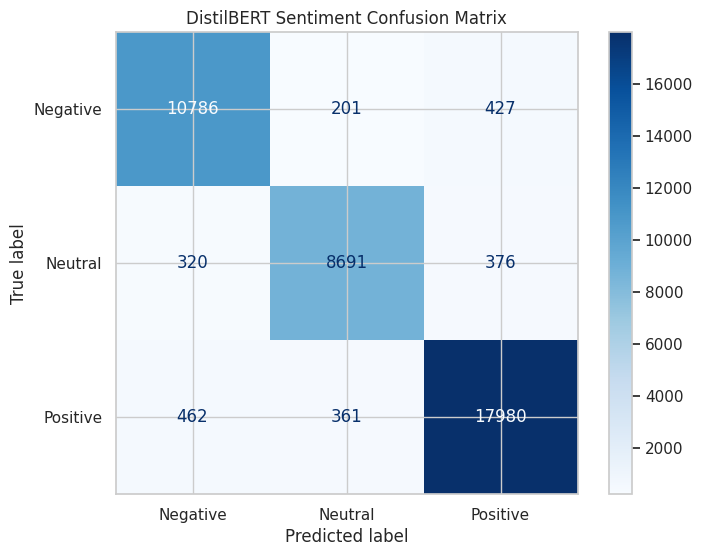

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

fig, ax = plt.subplots(figsize=(8, 6))

display.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("DistilBERT Sentiment Confusion Matrix")
plt.show()

Mic Test

In [ ]:
import torch

def predict_sentiment(text):

    # Put model in evaluation mode
    model.eval()

    # Convert tweet into tokens
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    # Move tokens to the same device as the model
    device = next(model.parameters()).device
    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    # Make prediction
    with torch.no_grad():
        outputs = model(**inputs)

    # Convert logits into probabilities
    probabilities = torch.softmax(outputs.logits, dim=1)

    # Get predicted class
    predicted_class = torch.argmax(
        probabilities, dim=1
    ).item()

    # Get confidence
    confidence = probabilities[0][predicted_class].item()

    return {
        "text": text,
        "sentiment": model.config.id2label[predicted_class],
        "confidence": round(confidence, 4),
        "probabilities": {
            model.config.id2label[i]: round(
                probabilities[0][i].item(), 4
            )
            for i in range(3)
        }
    }

print("Prediction function created successfully!")

Prediction function created successfully!


In [ ]:
test_tweets = [
    "The airline provided excellent customer service. Thank you!",
    "My flight was cancelled and nobody is helping me.",
    "What time does boarding begin?",
    "Amazing! Another five hours waiting at the airport!",
    "I received my refund. Thank you for your assistance."
]

for tweet in test_tweets:
    result = predict_sentiment(tweet)

    print("Tweet:", result["text"])
    print("Predicted sentiment:", result["sentiment"])
    print("Confidence:", result["confidence"])
    print("-" * 70)

Tweet: The airline provided excellent customer service. Thank you!
Predicted sentiment: Positive
Confidence: 0.9997
----------------------------------------------------------------------
Tweet: My flight was cancelled and nobody is helping me.
Predicted sentiment: Negative
Confidence: 0.7884
----------------------------------------------------------------------
Tweet: What time does boarding begin?
Predicted sentiment: Neutral
Confidence: 0.9994
----------------------------------------------------------------------
Tweet: Amazing! Another five hours waiting at the airport!
Predicted sentiment: Positive
Confidence: 0.9995
----------------------------------------------------------------------
Tweet: I received my refund. Thank you for your assistance.
Predicted sentiment: Positive
Confidence: 0.9995
----------------------------------------------------------------------


save model

In [ ]:
model_path = "/content/drive/MyDrive/data science/Phase 6/final_model"

trainer.save_model(model_path)
tokenizer.save_pretrained(model_path)

print("DistilBERT model saved successfully!")
print("Location:", model_path)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT model saved successfully!
Location: /content/drive/MyDrive/data science/Phase 6/final_model


Load your saved model

In [ ]:
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

model_path = "/content/drive/MyDrive/data science/Phase 6/final_model"

tokenizer = AutoTokenizer.from_pretrained(model_path)

model = AutoModelForSequenceClassification.from_pretrained(
    model_path
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)
model.eval()

print("Model loaded successfully!")
print("Device:", device)
print("Classes:", model.config.id2label)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully!
Device: cuda
Classes: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}


A batch prediction function

In [ ]:
def predict_batch(texts, batch_size=32):

    all_predictions = []
    all_confidences = []
    all_probabilities = []

    model.eval()

    for start in range(0, len(texts), batch_size):

        batch_texts = texts[start:start + batch_size]

        # Tokenize the batch
        inputs = tokenizer(
            batch_texts,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        )

        # Move inputs to GPU or CPU
        inputs = {
            key: value.to(device)
            for key, value in inputs.items()
        }

        # Generate predictions
        with torch.no_grad():
            outputs = model(**inputs)

        # Convert logits into probabilities
        probabilities = torch.softmax(
            outputs.logits,
            dim=1
        )

        # Predicted classes
        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        # Store results
        for prediction, probability in zip(
            predictions.cpu().numpy(),
            probabilities.cpu().numpy()
        ):

            predicted_label = model.config.id2label[
                int(prediction)
            ]

            confidence = float(probability[prediction])

            all_predictions.append(predicted_label)
            all_confidences.append(confidence)

            all_probabilities.append({
                model.config.id2label[i]: float(probability[i])
                for i in range(len(probability))
            })

    return (
        all_predictions,
        all_confidences,
        all_probabilities
    )

A function for CSV and Excel datasets

In [ ]:
def analyse_tweets(df, text_column="text", batch_size=32):

    # Check whether the text column exists
    if text_column not in df.columns:
        raise ValueError(
            f"Column '{text_column}' not found. "
            f"Available columns: {list(df.columns)}"
        )

    # Make a copy to preserve original data
    results_df = df.copy()

    # Prepare text
    texts = (
        results_df[text_column]
        .fillna("")
        .astype(str)
        .str.strip()
        .tolist()
    )

    # Identify empty messages
    valid_indices = [
        i for i, text in enumerate(texts) if text
    ]

    valid_texts = [texts[i] for i in valid_indices]

    # Initialise output columns
    results_df["predicted_sentiment"] = "Empty"
    results_df["confidence"] = np.nan

    results_df["negative_probability"] = np.nan
    results_df["neutral_probability"] = np.nan
    results_df["positive_probability"] = np.nan

    # Predict only non-empty messages
    if valid_texts:

        predictions, confidences, probabilities = predict_batch(
            valid_texts,
            batch_size=batch_size
        )

        for position, prediction, confidence, probability in zip(
            valid_indices,
            predictions,
            confidences,
            probabilities
        ):

            results_df.loc[
                results_df.index[position],
                "predicted_sentiment"
            ] = prediction

            results_df.loc[
                results_df.index[position],
                "confidence"
            ] = confidence

            results_df.loc[
                results_df.index[position],
                "negative_probability"
            ] = probability["Negative"]

            results_df.loc[
                results_df.index[position],
                "neutral_probability"
            ] = probability["Neutral"]

            results_df.loc[
                results_df.index[position],
                "positive_probability"
            ] = probability["Positive"]

    return results_df

In [ ]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

if filename.endswith(".csv"):
    new_tweets_df = pd.read_csv(filename)

elif filename.endswith((".xlsx", ".xls")):
    new_tweets_df = pd.read_excel(filename)

else:
    raise ValueError("Please upload a CSV or Excel file.")

print("Dataset loaded successfully!")
print("Shape:", new_tweets_df.shape)

display(new_tweets_df.head())

StopIteration: 